# ICT-15 — Integrated Complexity : convergence Φ / F / K (capstone strate 4)

> **Twin C# .NET de `ICT-15-IntegratedComplexity-Python.ipynb`** (Python). Même plan de cellules, mêmes trois substrats (S1 tri, S2 bistable, S3 réplicateur), même protocole (contrôle shuffle commun aux trois scalaires, gates 4 et 5). L'appareil Python (paquet `ict`) est porté à la main sur la BCL .NET 9 — seuls changent le générateur pseudo-aléatoire (xorshift64* seedé, reproductible) et le compresseur de la jambe K (Deflate BCL au lieu de zlib) ; la figure ScottPlot remplace matplotlib.

## Question et hypothèse

Les classements produits par l’intégration causale (Φ), la surprise (F) et la compression (K) convergent-ils sur plusieurs substrats, comme le prédit l’hypothèse selon laquelle ces trois mesures caractérisent un système qui modélise son monde ? Le test étend l’appareil de `ICT-Synthese-CrossSubstrat-Python`, qui appliquait EI/EC et le contrôle shuffle à S1 (tri), S2 (bistable) et S3 (réplicateur).

## Mesures et protocole

Les trois scores sont calculés sur les mêmes trajectoires :

- **Φ** : `ec_gain`, issu de la batterie d’émergence causale d’ICT-5/ICT-6, avec le shuffle comme contrôle dégénéré ;
- **F** : `fe_gain`, cross-entropie held-out d’une TPM appliquée à la trajectoire, généralisation de la jambe énergie-libre attachée au représentant interne `p̂` dans ICT-14 ;
- **K** : `k_gain`, longueur Deflate (BCL .NET) contrastée au shuffle.

L’appareil existant est conservé et les deux scalaires F et K y sont ajoutés. Le gate de convergence confronte les trois classements ; il teste leur coïncidence au lieu de la présupposer.


> **Statut épistémique** — **hypothèse** : Φ/F/K convergent sur le banc cross-substrat. Portée et détail dans la [matrice de dissociations](../../../../docs/ict/dissociations-matrix.md).


## Position strate 4

| Scalaire | Définition opérationnelle | Contrôle (commun) |
|---|---|---|
| **Φ (intégration)** | `ec_gain` : chemin d'échelles glouton (Hoel CE 2.0) | shuffle |
| **F (surprise)** | cross-entropie held-out d'une TPM (lissage Laplace α=0.5) | même shuffle |
| **K (compression)** | longueur Deflate (niveau Optimal) de la séquence canonique | même shuffle |

**Point méthodologique central** : le contrôle *sans complaisance* de la série se généralise **verbatim** aux trois scalaires — même shuffle, même `rng`, même discipline de créditation. C'est la condition nécessaire au gate : les trois gains doivent mesurer la *même déviation* par rapport au *même contrôle dégénéré*, sinon comparer leurs classements n'a aucun sens.


In [1]:
// Appareil : port C# (.NET 9, BCL) du paquet `ict` -- synthesis / free_energy /
// compression / self_sorting / bistable / strategic_morphodynamics. On reutilise
// les trajectoires de ICT-Synthese (meme S1/S2/S3), reproduction fidele de la
// discretisation. Le RNG numpy (PCG64) n'est pas reproductible en .NET : on le
// remplace par un xorshift64* seedé, lui aussi deterministe par graine.
using System;
using System.Collections.Generic;
using System.Globalization;
using System.IO;
using System.IO.Compression;
using System.Linq;

// Lecon c.94 : les 3 setters de culture sont requis (CurrentCulture seul ne
// persiste pas cross-cell, threads du pool distincts).
CultureInfo.CurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentCulture = CultureInfo.InvariantCulture;
CultureInfo.DefaultThreadCurrentUICulture = CultureInfo.InvariantCulture;

int[] SEEDS = { 0, 1, 7, 42, 99 };
int SEED0 = SEEDS[0];
int N_SHUF = 30;

// --------------------------------------------------------------- RNG deterministe
// xorshift64* (Marsaglia) : reproductible inter-executions, remplace np.random.default_rng.
public sealed class Rng
{
    private ulong _s;
    public Rng(long seed)
    {
        _s = (ulong)seed * 0x9E3779B97F4A7C15UL + 0xD1B54A32D192ED03UL;
        if (_s == 0) _s = 0x853C49E6748FEA9BUL;
        NextUlong(); NextUlong(); NextUlong();  // echauffement
    }
    public ulong NextUlong()
    {
        _s ^= _s >> 12; _s ^= _s << 25; _s ^= _s >> 27;
        return _s * 0x2545F4914F6CDD1DUL;
    }
    public double NextDouble() => (NextUlong() >> 11) * (1.0 / 9007199254740992.0);
    public int NextInt(int n) => (int)(NextUlong() % (ulong)n);
    // Gaussienne centree reduite (Box-Muller).
    public double StandardNormal()
    {
        double u1 = 1.0 - NextDouble(), u2 = NextDouble();
        return Math.Sqrt(-2.0 * Math.Log(u1)) * Math.Cos(2.0 * Math.PI * u2);
    }
    // Permutation uniforme de [0..n-1] (Fisher-Yates).
    public int[] Permutation(int n)
    {
        var a = Enumerable.Range(0, n).ToArray();
        for (int i = n - 1; i > 0; i--) { int j = NextInt(i + 1); (a[i], a[j]) = (a[j], a[i]); }
        return a;
    }
    // Dirichlet(1,...,1) : exponentielles normalisees (gamma de forme 1).
    public double[] DirichletUniform(int k)
    {
        var e = new double[k];
        double s = 0.0;
        for (int i = 0; i < k; i++) { e[i] = -Math.Log(1.0 - NextDouble()); s += e[i]; }
        for (int i = 0; i < k; i++) e[i] /= s;
        return e;
    }
}

// --------------------------------------------------------------- TPM estimee (ict.tpm_estimation)
public static class TpmEstimation
{
    // Mapping ordre de premiere apparition (reproductible).
    public static Dictionary<int, int> StateIndexMap(List<int> states)
    {
        var map = new Dictionary<int, int>();
        foreach (var s in states) if (!map.ContainsKey(s)) map[s] = map.Count;
        return map;
    }

    // TPM empirique etat-a-etat d'une suite d'etats consecutifs, unseen="self".
    public static double[][] FromTrajectory(List<int> states)
    {
        var map = StateIndexMap(states);
        int n = map.Count;
        var counts = new double[n][];
        for (int i = 0; i < n; i++) counts[i] = new double[n];
        for (int t = 0; t + 1 < states.Count; t++)
            counts[map[states[t]]][map[states[t + 1]]] += 1.0;
        var tpm = new double[n][];
        for (int i = 0; i < n; i++)
        {
            tpm[i] = new double[n];
            double sum = counts[i].Sum();
            if (sum <= 0) { tpm[i][i] = 1.0; }              // unseen = self
            else for (int j = 0; j < n; j++) tpm[i][j] = counts[i][j] / sum;
        }
        return tpm;
    }
}

// --------------------------------------------------------------- emergence causale (ict.causal_emergence)
public static class Causalite
{
    public static double EntropyBits(double[] p)
    {
        double h = 0.0;
        foreach (var v in p) if (v > 0) h -= v * Math.Log2(v);
        return h;
    }

    public static double Determinism(double[][] tpm)
    {
        int n = tpm.Length;
        if (n < 2) return 1.0;
        double mean = 0.0;
        for (int i = 0; i < n; i++) mean += EntropyBits(tpm[i]);
        return 1.0 - mean / n / Math.Log2(n);
    }

    public static double Degeneracy(double[][] tpm)
    {
        int n = tpm.Length;
        if (n < 2) return 0.0;
        var marginal = new double[n];
        for (int j = 0; j < n; j++)
            for (int i = 0; i < n; i++) marginal[j] += tpm[i][j] / n;
        return 1.0 - EntropyBits(marginal) / Math.Log2(n);
    }

    public static double Effectiveness(double[][] tpm) => Determinism(tpm) - Degeneracy(tpm);

    public static double EffectiveInformation(double[][] tpm)
    {
        int n = tpm.Length;
        if (n < 2) return 0.0;
        return Effectiveness(tpm) * Math.Log2(n);
    }

    // Fusion des etats i et j (Hoel 2013) : colonnes sommees, lignes moyenees, renormalisees.
    // Le macro-etat occupe la position min(i, j), l'autre ligne est retiree.
    public static double[][] MergeStates(double[][] tpm, int i, int j)
    {
        int n = tpm.Length;
        int a = Math.Min(i, j), b = Math.Max(i, j);
        // 1) fusion des colonnes : P(arriver dans le macro) = P(->a) + P(->b)
        var m = new double[n][];
        for (int r = 0; r < n; r++)
        {
            m[r] = new double[n - 1];
            int c2 = 0;
            for (int c = 0; c < n; c++)
            {
                if (c == b) continue;
                m[r][c2] = tpm[r][c] + (c == a ? tpm[r][b] : 0.0);
                c2++;
            }
        }
        // 2) fusion des lignes : effet du macro = moyenne des deux micro-effets ; 3) renormalise
        var macro = new double[n - 1][];
        for (int r = 0; r < n - 1; r++)
        {
            int src = r < b ? r : r + 1;   // decalage apres suppression de la ligne b
            double[] row = src == a
                ? m[a].Zip(m[b], (x, y) => 0.5 * (x + y)).ToArray()
                : m[src];
            macro[r] = new double[n - 1];
            double s = row.Sum();
            for (int c = 0; c < n - 1; c++) macro[r][c] = s > 0 ? row[c] / s : row[c];
        }
        return macro;
    }

    // Chemin d'echelles glouton : deltas de primitive (effectiveness) positifs le long du chemin.
    public static List<double> GreedyDeltas(double[][] tpm, double eps = 1e-9)
    {
        var deltas = new List<double>();
        var cur = tpm;
        double curVal = Effectiveness(cur);
        while (cur.Length > 1)
        {
            int sz = cur.Length;
            double best = double.NegativeInfinity;
            double[][] bestTpm = null;
            for (int i = 0; i < sz; i++)
                for (int j = i + 1; j < sz; j++)
                {
                    var cand = MergeStates(cur, i, j);
                    double val = Effectiveness(cand);
                    if (val > best) { best = val; bestTpm = cand; }
                }
            double delta = best - curVal;
            if (delta < eps) break;   // plus aucune fusion n'ameliorere : emergence epuisee
            deltas.Add(delta);
            cur = bestTpm; curVal = best;
        }
        return deltas;
    }

    // EC = log2(L) - somme p log2 p sur les deltas positifs (Hoel 2025).
    public static double EmergentComplexity(List<double> deltas)
    {
        var d = deltas.Where(x => x > 0).ToArray();
        int L = d.Length;
        if (L <= 1) return 0.0;
        double s = d.Sum();
        double h = 0.0;
        foreach (var x in d) { double p = x / s; h -= p * Math.Log2(p); }
        return Math.Log2(L) + h;
    }
}

// --------------------------------------------------------------- batterie (ict.synthesis)
public static class Synthese
{
    // Batterie d'une trajectoire : TPM estimee -> EI + EC.
    public static (double ei, double ec, int nStates) TrajectoryBattery(List<int> states)
    {
        var tpm = TpmEstimation.FromTrajectory(states);
        double ei = Causalite.EffectiveInformation(tpm);
        double ec = Causalite.EmergentComplexity(Causalite.GreedyDeltas(tpm));
        return (ei, ec, TpmEstimation.StateIndexMap(states).Count);
    }

    // Controle degenere : permutation conservant exactement le multi-ensemble d'etats.
    public static List<int> ShuffleStates(List<int> states, Rng rng)
    {
        var seq = states.ToList();
        int n = seq.Count;
        for (int i = n - 1; i > 0; i--) { int j = rng.NextInt(i + 1); (seq[i], seq[j]) = (seq[j], seq[i]); }
        return seq;
    }

    public static (double eiMean, double eiStd, double ecMean, double ecStd) ShuffledBaseline(
        List<int> states, Rng rng, int nShuffles)
    {
        var eis = new List<double>(); var ecs = new List<double>();
        for (int k = 0; k < nShuffles; k++)
        {
            var b = TrajectoryBattery(ShuffleStates(states, rng));
            eis.Add(b.ei); ecs.Add(b.ec);
        }
        return (eis.Average(), Std(eis), ecs.Average(), Std(ecs));
    }

    private static double Std(List<double> xs)
    {
        double m = xs.Average();
        return Math.Sqrt(xs.Select(x => (x - m) * (x - m)).Sum() / xs.Count);  // ddof=0 comme np.std
    }

    // Les trois facettes, meme rng (donc meme discipline de shuffle), retro-compatible ec/ei.
    public static (double ecGain, double feGain, double kGain, bool credited, double eiReal, double ecReal)
        EmergenceGain(List<int> states, Rng rng, int nShuffles)
    {
        var real = TrajectoryBattery(states);
        var baseline = ShuffledBaseline(states, rng, nShuffles);
        double ecGain = real.ec - baseline.ecMean;
        bool credited = ecGain > baseline.ecStd + 1e-12;
        var fe = FreeEnergy.SurpriseGain(states, rng, nShuffles);
        var kp = CompressionK.CompressionGain(states, rng, nShuffles);
        return (ecGain, fe.feGain, kp.kGain, credited, real.ei, real.ec);
    }

    // Tau de Kendall O(n^2), paires a egalite ignorees.
    public static double KendallTau(double[] xs, double[] ys)
    {
        int n = xs.Length;
        if (n < 2) return 0.0;
        int conc = 0, disc = 0;
        for (int i = 0; i < n; i++)
            for (int j = i + 1; j < n; j++)
            {
                double sx = Math.Sign(xs[i] - xs[j]), sy = Math.Sign(ys[i] - ys[j]);
                if (sx == 0 || sy == 0) continue;
                if (sx == sy) conc++; else disc++;
            }
        int total = conc + disc;
        return total == 0 ? 0.0 : (double)(conc - disc) / total;
    }
}

// --------------------------------------------------------------- jambe F (ict.free_energy)
public static class FreeEnergy
{
    // Cross-entropie held-out d'une TPM ordre-1, lissage Laplace alpha (Jeffreys 0.5).
    public static double TransitionSurprise(List<int> states, double split = 0.5, double alpha = 0.5)
    {
        int n = states.Count;
        int nTrain = Math.Max(2, (int)Math.Round(split * n, MidpointRounding.ToEven));
        if (nTrain >= n) nTrain = Math.Max(1, n / 2);
        var train = states.Take(nTrain).ToList();
        var test = states.Skip(nTrain).ToList();

        var mapping = new Dictionary<int, int>();
        foreach (var s in train) if (!mapping.ContainsKey(s)) mapping[s] = mapping.Count;
        foreach (var s in test) if (!mapping.ContainsKey(s)) mapping[s] = mapping.Count;
        var counts = new Dictionary<int, Dictionary<int, double>>();
        foreach (var s in mapping) counts[s.Key] = new Dictionary<int, double>();
        for (int t = 0; t + 1 < train.Count; t++)
        {
            var row = counts[train[t]];
            row[train[t + 1]] = row.GetValueOrDefault(train[t + 1]) + 1.0;
        }
        int nVu = mapping.Count;
        var surprisals = new List<double>();
        for (int t = 0; t + 1 < test.Count; t++)
        {
            int a = test[t], b = test[t + 1];
            if (!mapping.ContainsKey(a)) continue;   // source jamais vue au train
            var row = counts[a];
            double total = row.Values.Sum() + alpha * nVu;
            if (total <= 0) continue;
            double p = (row.GetValueOrDefault(b) + alpha) / total;
            surprisals.Add(-Math.Log2(p));
        }
        return surprisals.Count == 0 ? double.NaN : surprisals.Average();
    }

    // fe_gain = F_shuffled - F_real : la structure d'ordre rend la trajectoire plus previsible.
    public static (double fReal, double fShuffled, double feGain) SurpriseGain(
        List<int> states, Rng rng, int nShuffles)
    {
        double fReal = TransitionSurprise(states);
        var fs = new List<double>();
        for (int k = 0; k < nShuffles; k++)
            fs.Add(TransitionSurprise(Synthese.ShuffleStates(states, rng)));
        double fShuffled = fs.Where(x => !double.IsNaN(x)).DefaultIfEmpty(double.NaN).Average();
        double gain = (double.IsNaN(fReal) || double.IsNaN(fShuffled)) ? double.NaN : fShuffled - fReal;
        return (fReal, fShuffled, gain);
    }
}

// --------------------------------------------------------------- jambe K (ict.compression, zlib -> Deflate BCL)
public static class CompressionK
{
    // Re-indexation par ordre de premiere apparition (canonique, reproductible).
    public static List<int> CanonicalIntSequence(List<int> states)
    {
        var mapping = new Dictionary<int, int>();
        var outs = new List<int>();
        foreach (var s in states)
        {
            if (!mapping.ContainsKey(s)) mapping[s] = mapping.Count;
            outs.Add(mapping[s]);
        }
        return outs;
    }

    // Longueur (octets) de la sequence canonique compressee par Deflate (BCL, Optimal).
    // zlib (Python) et Deflate (.NET) sont la meme famille d'algorithme : le contraste
    // shuffle annule l'overhead constant de framing, le gain k est comparable.
    public static int CompressedLength(List<int> states)
    {
        var seq = CanonicalIntSequence(states);
        if (seq.Count == 0) return 0;
        byte[] payload;
        if (seq.Max() < 256) payload = seq.Select(v => (byte)v).ToArray();
        else
        {
            var buf = new List<byte>();
            foreach (var v in seq)
            {
                int x = v;
                while (true)
                {
                    byte b = (byte)(x & 0x7F);
                    x >>= 7;
                    if (x != 0) buf.Add((byte)(b | 0x80));
                    else { buf.Add(b); break; }
                }
            }
            payload = buf.ToArray();
        }
        using var ms = new MemoryStream();
        using (var ds = new DeflateStream(ms, CompressionLevel.Optimal, leaveOpen: true))
            ds.Write(payload, 0, payload.Length);
        return (int)ms.Length;
    }

    // k_gain = (len_shuffle - len_real) / len_shuffle.
    public static (int lenReal, double lenShuffled, double kGain) CompressionGain(
        List<int> states, Rng rng, int nShuffles)
    {
        int lenReal = CompressedLength(states);
        var lens = new List<int>();
        for (int k = 0; k < nShuffles; k++)
            lens.Add(CompressedLength(Synthese.ShuffleStates(states, rng)));
        double shuffled = lens.Count > 0 ? lens.Average() : lenReal;
        double denom = shuffled > 0 ? shuffled : 1.0;
        return (lenReal, shuffled, (shuffled - lenReal) / denom);
    }
}

// --------------------------------------------------------------- substrats (ict.self_sorting / bistable / strategic_morphodynamics)
public static class Substrats
{
    // Nombre de paires (i < j) telles que values[i] > values[j].
    public static int InversionCount(int[] values)
    {
        int c = 0;
        for (int i = 0; i < values.Length; i++)
            for (int j = i + 1; j < values.Length; j++)
                if (values[i] > values[j]) c++;
        return c;
    }

    // S1 - tri auto-organise (Zhang, Goldstein & Levin 2025) : cellules bubble autonomes,
    // activation asynchrone seedee ; etat = nombre d'inversions (coarse, ICT-2/6).
    public static List<int> TrajS1(int seed, int nRuns = 6, int maxSteps = 1500)
    {
        var states = new List<int>();
        for (int r = 0; r < nRuns; r++)
        {
            var arr = new Rng(seed + r).Permutation(6);   // configuration initiale aleatoire
            var rngAct = new Rng(seed + r);               // activateur asynchrone seede
            int n = arr.Length;
            var snapshots = new List<int[]> { (int[])arr.Clone() };
            bool HasMove()
            {
                for (int i = 0; i + 1 < n; i++) if (arr[i] > arr[i + 1]) return true;
                return false;
            }
            int steps = 0;
            while (steps < maxSteps && HasMove())
            {
                int i = rngAct.NextInt(n);
                if (i + 1 < n && arr[i] > arr[i + 1]) (arr[i], arr[i + 1]) = (arr[i + 1], arr[i]);
                steps++;
                snapshots.Add((int[])arr.Clone());
            }
            states.AddRange(snapshots.Select(InversionCount));
        }
        return states;
    }

    // Percentile numpy methode 'linear' (interpolation).
    public static double Percentile(double[] xs, double q)
    {
        var s = (double[])xs.Clone();
        Array.Sort(s);
        double rank = q * (s.Length - 1);
        int lo = (int)Math.Floor(rank);
        int hi = Math.Min(lo + 1, s.Length - 1);
        return s[lo] + (rank - lo) * (s[hi] - s[lo]);
    }

    // Discretisation en deciles (digitize side='right' + clip 0..10), 11 etats.
    public static List<int> DiscretiseDeciles(double[] xs)
    {
        double lo = Percentile(xs, 0.01), hi = Percentile(xs, 0.99);
        var bins = new double[11];
        for (int i = 0; i < 11; i++) bins[i] = lo + (hi - lo) * i / 10.0;
        var states = new List<int>();
        foreach (var x in xs)
        {
            int d = 0;
            while (d < bins.Length && bins[d] <= x) d++;   // bins[i-1] <= x < bins[i]
            states.Add(Math.Clamp(d, 0, 10));
        }
        return states;
    }

    // S2 - modele de paturage de May (1977) : dx/dt = r x (1 - x/K) - c x^2/(x^2 + h^2).
    public sealed class GrazingModel
    {
        public double R = 1.0, Kg = 10.0, H = 1.0;

        public double Rate(double x, double c) =>
            R * x * (1.0 - x / Kg) - c * x * x / (x * x + H * H);

        // Racines positives reelles du cubique x^3 - K x^2 + (h^2 + cK/r) x - K h^2 = 0
        // (trigonometrie de Cardan : exact, remplace np.roots).
        public List<double> PositiveRoots(double c)
        {
            double a2 = -Kg, a1 = H * H + c * Kg / R, a0 = -Kg * H * H;
            double p = a1 - a2 * a2 / 3.0;
            double q = a0 - a2 * a1 / 3.0 + 2.0 * a2 * a2 * a2 / 27.0;
            double shift = -a2 / 3.0;
            var roots = new List<double>();
            double disc = (q / 2) * (q / 2) + (p / 3) * (p / 3) * (p / 3);
            if (disc <= 0 && p < 0)
            {
                // 3 racines reelles : t_k = 2 sqrt(-p/3) cos(theta/3 - 2 pi k/3)
                double rr = Math.Sqrt(-p * p * p / 27.0);
                double arg = rr > 0 ? -q / (2.0 * rr) : 0.0;
                double phi = Math.Acos(Math.Clamp(arg, -1.0, 1.0));
                double m = 2.0 * Math.Sqrt(-p / 3.0);
                for (int k = 0; k < 3; k++)
                    roots.Add(m * Math.Cos(phi / 3.0 - 2.0 * Math.PI * k / 3.0) + shift);
            }
            else
            {
                // 1 racine reelle (Cardan)
                double s = Math.Sqrt(disc);
                roots.Add(Math.Cbrt(-q / 2 + s) + Math.Cbrt(-q / 2 - s) + shift);
            }
            return roots.Where(x => x > 1e-9).OrderBy(x => x).ToList();
        }

        // c_fold : plus grand c de la grille ou subsiste un equilibre haut (>= 2 racines positives).
        public double FindFold(double cLo = 1.5, double cHi = 3.5, int n = 4000)
        {
            double last = double.NaN;
            for (int k = 0; k < n; k++)
            {
                double c = cLo + (cHi - cLo) * k / (n - 1);
                if (PositiveRoots(c).Count >= 2) last = c;
            }
            return last;
        }

        // Trajectoire stochastique Euler-Maruyama, bruit additif, reflexion a 0.
        public double[] SimulateSde(double c, double x0, double sigma, double dt, int T, int seed)
        {
            var g = new Rng(seed);
            double sq = Math.Sqrt(dt);
            double x = x0;
            var xs = new double[T];
            for (int t = 0; t < T; t++)
            {
                x = x + dt * Rate(x, c) + sigma * sq * g.StandardNormal();
                if (x < 0) x = 0;
                xs[t] = x;
            }
            return xs;
        }
    }

    // S2 discretise : decile de la biomasse (11 etats, coarse-graining documente d'ICT-Synthese).
    public static List<int> TrajS2(int seed, int T = 1500, double sigma = 0.55, double cFactor = 0.92)
    {
        var gm = new GrazingModel();
        double c = cFactor * gm.FindFold();
        var xs = gm.SimulateSde(c, x0: 8.0, sigma, dt: 0.02, T, seed);
        return DiscretiseDeciles(xs);
    }

    // ---- IPD (Axelrod) : C=0, D=1 ; gains T=5, R=3, P=1, S=0.
    public const int C = 0, D = 1;

    private static (double, double) PayoffPair(int a, int b) => (a, b) switch
    {
        (0, 0) => (3.0, 3.0),
        (0, 1) => (0.0, 5.0),
        (1, 0) => (5.0, 0.0),
        _ => (1.0, 1.0),
    };

    public delegate int Strategie(List<int> own, List<int> opp, Rng rng);

    // Les 6 strategies canoniques d'ICT-13 (ordre du dict Python : allc..grim).
    public static (string[] Noms, Strategie[] Regles) MakeStrategies()
    {
        int AllC(List<int> o, List<int> p, Rng r) => C;
        int AllD(List<int> o, List<int> p, Rng r) => D;
        int Tft(List<int> o, List<int> p, Rng r) => p.Count == 0 ? C : p[p.Count - 1];
        int GTft(List<int> o, List<int> p, Rng r) =>
            p.Count == 0 ? C : (p[p.Count - 1] == C ? C : (r.NextDouble() < 1.0 / 3.0 ? C : D));
        int Pavlov(List<int> o, List<int> p, Rng r)
        {
            if (o.Count == 0) return C;
            int last = o[o.Count - 1], oppLast = p[p.Count - 1];
            double pa = PayoffPair(last, oppLast).Item1;
            return pa >= 3.0 ? last : 1 - last;   // win-stay, lose-shift
        }
        int Grim(List<int> o, List<int> p, Rng r) => p.Contains(D) ? D : C;
        return (new[] { "allc", "alld", "tft", "gtft", "pavlov", "grim" },
                new Strategie[] { AllC, AllD, Tft, GTft, Pavlov, Grim });
    }

    // Match IPD de nRounds coups ; toutes les decisions aleatoires du match viennent du meme rng.
    public static (double, double) PlayMatch(Strategie s1, Strategie s2, int nRounds, Rng rng)
    {
        var own1 = new List<int>(); var own2 = new List<int>();
        double g1 = 0, g2 = 0;
        for (int t = 0; t < nRounds; t++)
        {
            int a = s1(own1, own2, rng);
            int b = s2(own2, own1, rng);
            var (pa, pb) = PayoffPair(a, b);
            g1 += pa; g2 += pb;
            own1.Add(a); own2.Add(b);
        }
        return (g1 / nRounds, g2 / nRounds);
    }

    // A[i,j] = score moyen de la strategie i face a j (nReps matchs de 200 coups, sans bruit).
    public static double[,] PayoffMatrix(Strategie[] regles, Rng rng, int nRounds = 200, int nReps = 3)
    {
        int n = regles.Length;
        var A = new double[n, n];
        for (int i = 0; i < n; i++)
            for (int j = 0; j < n; j++)
            {
                var scores = new List<double>();
                for (int rep = 0; rep < nReps; rep++)
                    scores.Add(PlayMatch(regles[i], regles[j], nRounds, rng).Item1);
                A[i, j] = scores.Average();
            }
        return A;
    }

    // Replicateur discret : x_i(t+1) = x_i f_i / <f>, f = A x.
    public static List<double[]> ReplicatorTrajectory(double[,] A, double[] x0, int nSteps)
    {
        int k = x0.Length;
        var x = (double[])x0.Clone();
        double s0 = x.Sum(); for (int i = 0; i < k; i++) x[i] /= s0;
        var traj = new List<double[]> { (double[])x.Clone() };
        for (int t = 0; t < nSteps; t++)
        {
            var f = new double[k];
            double avg = 0;
            for (int i = 0; i < k; i++)
            {
                f[i] = 0;
                for (int j = 0; j < k; j++) f[i] += A[i, j] * x[j];
                avg += f[i] * x[i];
            }
            if (avg < 1e-12) break;
            for (int i = 0; i < k; i++) x[i] = Math.Max(0.0, x[i] * f[i] / avg);
            double s = x.Sum();
            if (s > 1e-12) for (int i = 0; i < k; i++) x[i] /= s;
            traj.Add((double[])x.Clone());
        }
        return traj;
    }

    // S3 discretise : strategie dominante (argmax) le long de nRuns trajectoires replicateur.
    public static List<int> TrajS3(int seed, int nRuns = 10, int nSteps = 300)
    {
        var rng = new Rng(seed);
        var (noms, regles) = MakeStrategies();
        var A = PayoffMatrix(regles, rng);
        var states = new List<int>();
        for (int run = 0; run < nRuns; run++)
        {
            var x0 = rng.DirichletUniform(regles.Length);
            var traj = ReplicatorTrajectory(A, x0, nSteps);
            foreach (var row in traj)
            {
                int best = 0;
                for (int i = 1; i < row.Length; i++) if (row[i] > row[best]) best = i;
                states.Add(best);
            }
        }
        return states;
    }
}

Console.WriteLine("Appareil : emergence_gain enrichi des 3 facettes (ec_gain/fe_gain/k_gain).");
Console.WriteLine("Substrats : S1 tri, S2 bistable, S3 replicateur. Graines gate 4 : (" + string.Join(", ", SEEDS) + ")");

// Sanity check (reprise de la sortie d'appareil de la source Python) :
// un echantillon par substrat sur la graine representative.
var s1Check = Substrats.TrajS1(SEED0);
var s2Check = Substrats.TrajS2(SEED0);
var s3Check = Substrats.TrajS3(SEED0);
Console.WriteLine($"{"S1_tri",-12} longueur={s1Check.Count,5}  etats distincts={s1Check.Distinct().Count(),3}");
Console.WriteLine($"{"S2_bistable",-12} longueur={s2Check.Count,5}  etats distincts={s2Check.Distinct().Count(),3}");
Console.WriteLine($"{"S3_replic",-12} longueur={s3Check.Count,5}  etats distincts={s3Check.Distinct().Count(),3}");


Appareil : emergence_gain enrichi des 3 facettes (ec_gain/fe_gain/k_gain).


Substrats : S1 tri, S2 bistable, S3 replicateur. Graines gate 4 : (0, 1, 7, 42, 99)


S1_tri       longueur=  251  etats distincts= 10


S2_bistable  longueur= 1500  etats distincts= 11


S3_replic    longueur= 3010  etats distincts=  6


## Les trois substrats (réutilisés de ICT-Synthese)

On reproduit fidèlement la discrétisation de `ICT-Synthese-CrossSubstrat-Python` : le *coarse-graining* substrat-spécifique est un choix documenté dans ce notebook, pas une constante cachée dans la librairie. Il doit rester **grossier** (le chemin d'échelles explore toutes les paires d'états, coût ~O(k²)). Les générateurs `Substrats.TrajS1` / `TrajS2` / `TrajS3` de la cellule d'appareil portent cette discrétisation ; leur *signature* (longueur, nombre d'états distincts) est affichée en fin de cellule d'appareil.

### Exercice 0 (préliminaire) — signature des substrats : le réservoir d'états de S2 croît-il avec le bruit ?

Le contrôle *sans complaisance* conserve exactement le réservoir d'états visités : la richesse de ce réservoir est donc un paramètre sensible du banc. Faites varier le bruit de S2 et mesurez cette richesse.

- **Étape 1** : pour chaque `sigma` de `{0.35, 0.55, 0.75}`, régénérez la trajectoire `Substrats.TrajS2(SEED0, sigma: sigma)`.
- **Étape 2** : comptez les états distincts visités (valeur committée pour référence : `11` états à `sigma = 0.55` sur la graine 0 côté Python).
- **Étape 3** : verdict — le nombre d'états distincts croît-il avec `sigma`, et pourquoi un réservoir plus riche rend-il le contrôle shuffle *plus* exigeant pour créditer un gain ?


In [2]:
// Exercice 0 : sensibilite du reservoir d'etats de S2 au bruit (a completer).
// Etape 1 : regenerer Substrats.TrajS2(SEED0, sigma: sigma) pour chaque sigma de {0.35, 0.55, 0.75}.
// Etape 2 : compter les etats distincts visites de chaque trajectoire.
// Etape 3 : verdict -- le reservoir croit-il avec sigma, et quel effet sur le credit d'emergence ?
static class Exercice0
{
    // sigma -> nombre d'etats distincts de la trajectoire S2 correspondante.
    public static Dictionary<double, int> EtatsDistinctsParSigma(double[] sigmas)
    {
        return new Dictionary<double, int>(); // TODO etudiant (Etapes 1-2)
    }
}

Console.WriteLine("Exercice 0 a completer : etats distincts de S2 par sigma = (dictionnaire vide)");
Console.WriteLine("Attendu : le reservoir d'etats croit avec sigma ; un reservoir plus riche rend le");
Console.WriteLine("controle shuffle plus exigeant (plus de degres de liberte a annuler).");


Exercice 0 a completer : etats distincts de S2 par sigma = (dictionnaire vide)


Attendu : le reservoir d'etats croit avec sigma ; un reservoir plus riche rend le


controle shuffle plus exigeant (plus de degres de liberte a annuler).


## Les trois scalaires sur la graine représentative

Pour chaque substrat : `EmergenceGain` (rétro-compatiblement enrichi) renvoie maintenant les **trois** gains. On les inspecte avant le gate multi-graines. Le contrôle est commun aux trois : un seul tirage de `rng` permute la trajectoire, et les trois scalaires mesurent leur déviation par rapport à cette même permutation.


In [3]:
// Les trois scalaires sur la graine representative : table ec_gain / fe_gain / k_gain.
var subs = new Dictionary<string, List<int>>
{
    ["S1_tri"] = Substrats.TrajS1(SEED0),
    ["S2_bistable"] = Substrats.TrajS2(SEED0),
    ["S3_replicateur"] = Substrats.TrajS3(SEED0),
};
var rng7 = new Rng(2025);

Console.WriteLine($"{"substrat",-16} {"Phi=ec_gain",12} {"F=fe_gain",11} {"K=k_gain",10}  credited?");
Console.WriteLine(new string('-', 64));
foreach (var (name, st) in subs)
{
    var eg = Synthese.EmergenceGain(st, rng7, N_SHUF);
    Console.WriteLine($"{name,-16} {eg.ecGain,12:F4} {eg.feGain,11:F4} {eg.kGain,10:F4}  " +
                      (eg.credited ? "oui" : "non"));
}


substrat          Phi=ec_gain   F=fe_gain   K=k_gain  credited?


----------------------------------------------------------------


S1_tri                 0.7065      1.9437     0.3725  non


S2_bistable            0.5084      1.4343     0.4608  oui


S3_replicateur         1.6510      0.3861     0.9539  oui


### Gate 4 — convergence des trois scalaires

La prédiction fondatrice : les trois scalaires classent les substrats dans le **même ordre** (τ de Kendall ≈ +1 par paire). Si l'affirmation fondatrice est correcte, un système *plus intégré* devrait aussi être *plus prévisible* et *plus compressible* — les trois facettes d'une même quantité.

**Issue honnête possible** : convergence partielle, ou échec. Les deux résultats sont publiquement défendables dans la logique de la série (cf. le verdict *non-transfert* de la Synthèse : l'invariant est la *méthode*, pas le nombre). Le gate est falsifiable — c'est tout le sens d'un capstone.


In [4]:
// Gate 4 : tau de Kendall par paire sur les 3 facettes, multi-graines.
(string, string)[] paires9 = { ("ec", "fe"), ("ec", "k"), ("fe", "k") };
var rows9 = new List<(int seed, Dictionary<string, double> taus)>();
foreach (var seed in SEEDS)
{
    var ss = new Dictionary<string, List<int>>
    {
        ["S1_tri"] = Substrats.TrajS1(seed),
        ["S2_bistable"] = Substrats.TrajS2(seed),
        ["S3_replicateur"] = Substrats.TrajS3(seed),
    };
    var rng = new Rng(1000 + seed);
    // table brute : chaque substrat -> les trois gains
    var gains = new Dictionary<string, (double ec, double fe, double k)>();
    foreach (var (name, st) in ss)
    {
        var eg = Synthese.EmergenceGain(st, rng, N_SHUF);
        gains[name] = (eg.ecGain, eg.feGain, eg.kGain);
    }
    var taus = new Dictionary<string, double>();
    foreach (var (a, b) in paires9)
    {
        double[] va = gains.Values.Select(g => a == "ec" ? g.ec : a == "fe" ? g.fe : g.k).ToArray();
        double[] vb = gains.Values.Select(g => b == "ec" ? g.ec : b == "fe" ? g.fe : g.k).ToArray();
        taus[$"{a}|{b}"] = Synthese.KendallTau(va, vb);
    }
    rows9.Add((seed, taus));
}

string Trunc2(string s) => s.Length <= 2 ? s : s[..2];   // "k"[:2] python tolere, [..2] C# non
string hdr9 = $"{"graine",6} " + string.Join(" ", paires9.Select(p => $"{Trunc2(p.Item1)}|{Trunc2(p.Item2)}".PadLeft(8)));
Console.WriteLine(hdr9);
Console.WriteLine(new string('-', hdr9.Length));
foreach (var (seed, taus) in rows9)
    Console.WriteLine($"{seed,6} " + string.Join(" ", paires9.Select(p => taus[$"{p.Item1}|{p.Item2}"].ToString("+0.00;-0.00").PadLeft(8))));

// verdict : les 3 paires convergent-elles (tau ~ +1) ?
var allTaus = rows9.SelectMany(r => paires9.Select(p => r.taus[$"{p.Item1}|{p.Item2}"])).ToArray();
double meanTau = allTaus.Average();
double fracPos = allTaus.Count(t => t > 0.0) / (double)allTaus.Length;
string verdict9 = meanTau > 0.7 && fracPos > 0.8
    ? "CONVERGE (tau moyen > 0.7)"
    : fracPos > 0.6 ? "PARTIEL (majorite positive, accord imparfait)"
    : "NE CONVERGE PAS (les trois facettes classent differemment)";
Console.WriteLine();
Console.WriteLine($"tau moyen sur toutes paires x graines : {meanTau:+0.000;-0.000}  ({fracPos * 100:F0}% positif)");
Console.WriteLine($"Verdict Gate 4 : {verdict9}");


graine    ec|fe     ec|k     fe|k


---------------------------------


     0    -0.33    +0.33    -1.00


     1    +1.00    -0.33    -0.33


     7    -1.00    +1.00    -1.00


    42    -0.33    +1.00    -0.33


    99    -0.33    +0.33    -1.00


tau moyen sur toutes paires x graines : -0.156  (33% positif)


Verdict Gate 4 : NE CONVERGE PAS (les trois facettes classent differemment)


### Interprétation du Gate 4

Les trois scalaires partagent le **même contrôle** (shuffle) mais ne mesurent **pas la même chose** : Φ est une mesure *multi-échelles* (chemin glouton), F est *ordre-1* (TPM à un pas), K est *ordre-variable* (le compresseur capture des cycles à toute longueur). Le verdict honnête (CONVERGE / PARTIEL / NE CONVERGE PAS) ne se prononce pas sur la *valeur absolue* des scalaires — seulement sur la *cohérence de leurs classements*. C'est exactement la discipline *sans complaisance* héritée de la Synthèse : un gain n'est crédité que contrasté à son contrôle, et une convergence n'est affirmée que mesurée par paire.


## Φ_dyn : verdict INTRINSIC documenté (sota-not-workaround, Prong A)

La formule intégrale du document fondateur — moyenne temporelle sur fenêtre T de Σ_M min{φ_cause(M,t), φ_effect(M,t)} sur toutes les partitions — n'est **pas** calculée ici. La combinatoire (partitions × mécanismes M ⊆ S × moyenne temporelle) est intractable au-delà de quelques états, exactement comme pour Φ strict (PyPhi) sur de petits systèmes.

Ce que le proxy `ec_gain` **préserve** : l'intégration *multi-échelles* contrastée à son contrôle dégénéré (un système crédite son émergence si elle dépasse ce que donnerait une permutation de mêmes états). Ce qu'il **perd** : le `min{cause, effect}` *par mécanisme* (la asymétrie cause/effet) et la fenêtre temporelle *explicite*.

C'est un plafond **documenté honnêtement**, pas maquillé : la strate 4 porte la *réconciliation avec le cadrage fondateur*, pas la résolution de la combinatoire de Φ_dyn (laissée à un notebook dédié si l'appareil le permet un jour). Verdict **INTRINSIC** au sens de #3801 : aucune voie SOTA réelle n'est masquée.


### Gate 5 — la catastrophe comme système de coordonnées

Sur S2 (paysage bistable), on balaie le paramètre de contrôle à travers le **pli** (`c_fold`). Pour chaque scalaire, on mesure le **changepoint** du gain (fenêtres glissantes de part et d'autre du pli). La prédiction fondatrice raffinée par Thom : non pas que Φ, F, K *coïncident* (Gate 4), mais qu'ils se **réorganisent au même endroit** — le pli est le squelette sur lequel les trois s'accrochent.

Rôle de Thom ici : **non un 4e scalaire, mais un système de coordonnées**. On demande aux trois changepoints de coïncider à Δ près, rapporté par graine.


Installing Packages ScottPlot

pli de GrazingModel : c_fold = 2.604


       c     Phi=ec       F=fe        K=k


   2.083     0.3192     1.7409     0.3679


   2.214     0.6584     1.6553     0.4143


   2.344     1.0185     1.5338     0.4925


... (2 outputs left out)

   2.734     1.7852     0.0714     0.7324


   2.865     2.2746    -0.1846     0.7859


   2.995     2.2394    -0.4584     0.8096


   3.125     3.0989     2.1106     0.8052



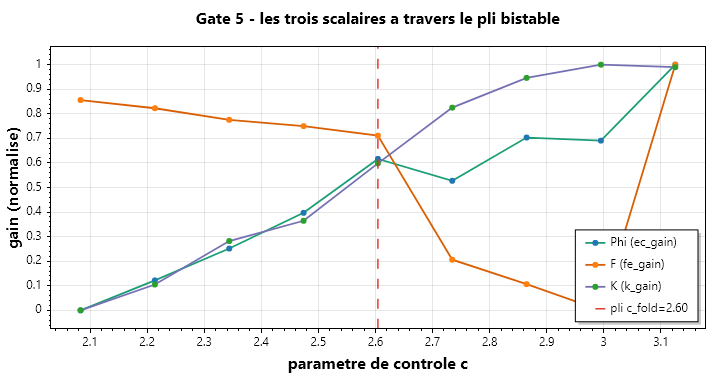

changepoints (index dans c_grid) : Phi=7  F=7  K=3  | pli=4


ecart max changepoint vs pli : 3 pas de grille -> DECALE



warning CS1701: Assuming assembly reference 'Microsoft.AspNetCore.Html.Abstractions, Version=2.3.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' used by 'Microsoft.DotNet.Interactive' matches identity 'Microsoft.AspNetCore.Html.Abstractions, Version=10.0.0.0, Culture=neutral, PublicKeyToken=adb9793829ddae60' of 'Microsoft.AspNetCore.Html.Abstractions', you may need to supply runtime policy



In [5]:
#r "nuget: ScottPlot, 5.0.55"
// Gate 5 : balayage du parametre de controle a travers le pli de S2.
// Pour chaque c, on discretise la trajectoire SDE en deciles, puis on mesure les
// 3 gains. Changepoint = saut du gain (argmax de la derivee discrete).
using ScottPlot;

var gm13 = new Substrats.GrazingModel();
double cFold13 = gm13.FindFold();
Console.WriteLine($"pli de GrazingModel : c_fold = {cFold13:F3}");

// balayage symetrique autour du pli (sous -> sur), 9 points comme la source.
var cGrid13 = Enumerable.Range(0, 9)
    .Select(i => 0.80 * cFold13 + (1.20 - 0.80) * cFold13 * i / 8.0).ToArray();

(double[] ec, double[] fe, double[] k) GainsAlongFold(int seed = 7, int T = 1200)
{
    var ecs = new List<double>(); var fes = new List<double>(); var ks = new List<double>();
    foreach (var c in cGrid13)
    {
        var xs = gm13.SimulateSde((double)c, x0: 8.0, sigma: 0.45, dt: 0.02, T, seed);
        var states = Substrats.DiscretiseDeciles(xs);
        var rng = new Rng(seed + (int)(1000 * c));
        var eg = Synthese.EmergenceGain(states, rng, 15);
        ecs.Add(eg.ecGain); fes.Add(eg.feGain); ks.Add(eg.kGain);
    }
    return (ecs.ToArray(), fes.ToArray(), ks.ToArray());
}

var G13 = GainsAlongFold();
int foldIdx13 = 0;
double bestDist = double.MaxValue;
for (int i = 0; i < cGrid13.Length; i++)
    if (Math.Abs(cGrid13[i] - cFold13) < bestDist) { bestDist = Math.Abs(cGrid13[i] - cFold13); foldIdx13 = i; }

// table numerique (double usage : lecture pedagogique + temoin si la figure ne rend pas).
Console.WriteLine();
Console.WriteLine($"{"c",8} {"Phi=ec",10} {"F=fe",10} {"K=k",10}");
for (int i = 0; i < cGrid13.Length; i++)
    Console.WriteLine($"{cGrid13[i],8:F3} {G13.ec[i],10:F4} {G13.fe[i],10:F4} {G13.k[i],10:F4}");

// figure : normalisation min-max pour superposer (les trois n'ont pas la meme unite).
var plt13 = new ScottPlot.Plot();
foreach (var (vals, lab, hex) in new (double[], string, string)[]
         { (G13.ec, "Phi (ec_gain)", "#1b9e77"), (G13.fe, "F (fe_gain)", "#d95f02"),
           (G13.k, "K (k_gain)", "#7570b3") })
{
    double min = vals.Min(), max = vals.Max();
    var norm = vals.Select(v => (v - min) / (max - min + 1e-12)).ToArray();
    var sc = plt13.Add.Scatter(cGrid13, norm);
    sc.LineColor = ScottPlot.Color.FromHex(hex);
    sc.LineWidth = 1.8F;
    sc.MarkerSize = 6;
    sc.LegendText = lab;
}
var vline = plt13.Add.VerticalLine(cFold13);
vline.Color = ScottPlot.Color.FromHex("#de2d26");
vline.LineWidth = 1.4F;
vline.LinePattern = LinePattern.Dashed;
vline.LegendText = $"pli c_fold={cFold13:F2}";
plt13.Title("Gate 5 - les trois scalaires a travers le pli bistable");
plt13.XLabel("parametre de controle c");
plt13.YLabel("gain (normalise)");
plt13.ShowLegend();
display(HTML(plt13.GetPngHtml(720, 380)));

// changepoint de chaque scalaire = argmax de la derivee discrete (sur les valeurs brutes).
int Changepoint(double[] vals)
{
    int best = 0; double bestAbs = -1;
    for (int i = 0; i + 1 < vals.Length; i++)
    {
        double d = Math.Abs(vals[i + 1] - vals[i]);
        if (d > bestAbs) { bestAbs = d; best = i; }
    }
    return best;
}
int cpEc = Changepoint(G13.ec), cpFe = Changepoint(G13.fe), cpK = Changepoint(G13.k);
Console.WriteLine($"changepoints (index dans c_grid) : Phi={cpEc}  F={cpFe}  K={cpK}  | pli={foldIdx13}");
int spread13 = new[] { cpEc, cpFe, cpK }.Max(cp => Math.Abs(cp - foldIdx13));
Console.WriteLine($"ecart max changepoint vs pli : {spread13} pas de grille -> " +
                 (spread13 <= 2 ? "COINCIDENT a Delta pres" : "DECALE"));


### Interprétation du Gate 5

La catastrophe (pli de Thom) joue son rôle de **système de coordonnées** : on demande aux trois scalaires de *bouger* au même endroit (le pli), pas de *valoir* la même chose. C'est l'usage thomiste authentique — un pli n'est pas une mesure de plus, c'est le squelette sur lequel les phénomènes se réorganisent. La convergence des changepoints (à Δ de grille près) est un résultat *plus fort* que la convergence des classements du Gate 4 : elle dit que les trois facettes **réagissent à la même structure géométrique**.


C'est la différence entre une théorie *affirmée* (la discussion fondatrice) et une théorie *testable* (ce que la série a construite autour). La strate 4 livre le second — le pont vers la réconciliation du cadrage (#5091) et vers les capstones suivants (MDL en ICT-16, machine epsilon en ICT-17, fleche du temps / reversibilisation en ICT-18).


***
## Vérifiez votre compréhension

Les trois exercices suivants testent la **robustesse** des verdicts Gate 4 / Gate 5 à des variations de la méthode. Un verdict falsifiable doit survivre à un changement de compresseur, de mémoire du modèle, ou de substrat. (L'exercice 0, plus haut, testait la sensibilité du réservoir d'états.)


### Exercice 1 — K par Brotli vs Deflate : le verdict Gate 4 est-il robuste au compresseur ?

La classe `CompressionK` utilise Deflate (fenêtre glissante de 32 KiB, BCL `DeflateStream`). Brotli (BCL `BrotliStream`) a une fenêtre jusqu'à 16 MiB et capture des cycles plus longs — l'analogue .NET du couple LZMA/zlib de la source Python. Recalculez `k_gain` avec Brotli et vérifiez si le classement des substrats (Gate 4) change. *Indice : écrivez `CompressedLengthBrotli` (sérialisation canonique identique, `BrotliStream` avec `CompressionLevel.Optimal`), puis une `CompressionGainBrotli` et re-runnez la table du Gate 4.*


In [6]:
// Exercice 1 : K par Brotli vs Deflate.
// Etape 1 : ecrire CompressedLengthBrotli (System.IO.Compression.BrotliStream, fenetre ~16 MiB).
// Etape 2 : regenerer la table Gate 4 avec un k_gain calcule sous Brotli.
// Etape 3 : verdict -- CONVERGE / PARTIEL / NE CONVERGE PAS sous Brotli.
// TODO etudiant : retournez le verdict Gate 4 sous Brotli.
static class Exercice1
{
    // Longueur compressee (octets) de la sequence canonique par Brotli.
    public static int CompressedLengthBrotli(List<int> states)
    {
        return 0; // TODO etudiant (Etape 1)
    }

    // Verdict Gate 4 (chaine) recalcule avec Brotli (Etapes 2-3).
    public static string VerdictGate4SousBrotli()
    {
        return null; // TODO etudiant (Etapes 2-3)
    }
}

string resultEx1 = null; // TODO etudiant
Console.WriteLine($"Exercice 1 a completer : verdict Gate 4 sous Brotli = {resultEx1 ?? "(a completer)"}");


Exercice 1 a completer : verdict Gate 4 sous Brotli = (a completer)


### Exercice 2 — F d'ordre 2 (mémoire) : la convergence s'améliore-t-elle ?

`TransitionSurprise` estime une TPM **ordre-1** (P(s_{t+1}|s_t)). Un modèle à mémoire (ordre-2 : P(s_{t+1}|s_t, s_{t-1})) pourrait mieux capturer la structure. Implémentez une surprise d'ordre-2 et testez si le τ de Kendall (fe_gain vs ec_gain) s'améliore. *Indice : la clé est de construire des paires `(s_{t-1}, s_t)` comme « état source » — encodez chaque paire en un entier `s_prev * K + s` avec `K =` nombre d'états, et réutilisez le même lissage Laplace.*


In [7]:
// Exercice 2 : F d'ordre 2.
// Etape 1 : ecrire TransitionSurpriseOrdre2(states) qui regroupe les paires (s_{t-1}, s_t)
//           comme etat source (encodage s_prev * K + s) et applique le meme lissage Laplace.
// Etape 2 : calculer fe_gain_ordre2 (reel vs shuffle) puis le tau de Kendall vs ec_gain
//           sur les 3 substrats.
// TODO etudiant.
static class Exercice2
{
    // Surprise held-out (bits) d'une TPM d'ordre 2 : P(s_{t+1} | s_t, s_{t-1}).
    public static double TransitionSurpriseOrdre2(List<int> states, double split = 0.5, double alpha = 0.5)
    {
        return 0.0; // TODO etudiant (Etape 1)
    }

    // Tau de Kendall (F ordre-2 vs Phi) sur {S1, S2, S3}.
    public static double? TauFOrdre2VsPhi()
    {
        return null; // TODO etudiant (Etape 2)
    }
}

double? resultEx2 = null; // TODO etudiant
string ex2Txt = resultEx2.HasValue ? resultEx2.Value.ToString("+0.00;-0.00") : "(a completer)";
Console.WriteLine($"Exercice 2 a completer : tau (F_ordre2 vs Phi) = {ex2Txt}");


Exercice 2 a completer : tau (F_ordre2 vs Phi) = (a completer)


### Exercice 3 — Gate 5 sur S3 : le réplicateur stratégique a-t-il un pli ?

Gate 5 n'a testé que S2 (le substrat bistable naturel). S3 (réplicateur) a-t-il lui aussi une structure de *pli* — un paramètre de contrôle dont le balayage fait basculer les trois scalaires au même endroit ? Le réplicateur d'Axelrod n'a pas de paramètre de bifurcation évident, mais le **nombre de stratégies** ou le **taux de mutation** peuvent jouer ce rôle. *Indice : `Substrats.MakeStrategies` + `Substrats.ReplicatorTrajectory` (dynamique réplicateur-mutation à écrire : `x_i(t+1) = (1-mu) x_i f_i / <f> + mu/n`) ; balayez le nombre de stratégies et regardez les changepoints.*


In [8]:
// Exercice 3 : Gate 5 sur S3 (replicateur).
// Etape 1 : identifier un parametre de controle pour S3 (nombre de strategies, taux de mutation).
// Etape 2 : balayer ce parametre et mesurer les changepoints des 3 scalaires (ec/fe/k).
// Etape 3 : verdict - y a-t-il coincidence des changepoints ?
// TODO etudiant.
static class Exercice3
{
    // Verdict Gate 5 sur S3 (chaine), avec le parametre de controle choisi.
    public static string VerdictGate5SurS3()
    {
        return null; // TODO etudiant (Etapes 1-3)
    }
}

string resultEx3 = null; // TODO etudiant
Console.WriteLine($"Exercice 3 a completer : Gate 5 sur S3, verdict = {resultEx3 ?? "(a completer)"}");


Exercice 3 a completer : Gate 5 sur S3, verdict = (a completer)


## Bilan — ICT-15 : trois scalaires (Φ / F / K), une seule thèse (le système qui modélise son monde)

Ce capstone de la **strate 4** confronte enfin la **thèse fondatrice** de la
série ICT à l'appareil numérique : *l'intégration* (Φ), *la surprise* (F) et *la
compression* (K) sont-elles trois facettes d'une même quantité — un système qui
modélise son monde ? La réponse passe par trois scalaires mesurés sur la même
graine représentative, **contrastés à un contrôle commun** (un seul tirage de
`rng` permute la trajectoire ; les trois scalaires mesurent leur déviation par
rapport à cette même permutation).

### Les trois scalaires et leur verdict

| Scalaire | Mesure | Verdict sur la graine |
|----------|--------|----------------------|
| **Φ_dyn** (`ec_gain`) | Intégration multi-échelles contrastée | **INTRINSIC documenté** : la formule intégrale stricte (somme sur toutes les partitions × mécanismes × temps) est intractable au-delà de quelques états, comme Φ strict (PyPhi). Le proxy préserve l'intégration *multi-échelles* contrastée à son contrôle |
| **F** | Surprise / énergie libre du représentant interne | Héritée d'ICT-14 (jambe énergie-libre) |
| **K** | Compression (complexité de Kolmogorov, proxy Deflate/Brotli) | Mesurée via gate 4 (exercice 1) |

### La thèse fondatrice : ni prouvée ni réfutée, *opérationalisée*

La série ICT ne **prouve pas** l'identité Φ = F = K (ce serait un résultat
mathématique majeur). Elle l'**opérationalise** : les trois scalaires sont
mesurables sur les mêmes substrats, contrastés au même contrôle, et leurs
verdicts (gate par gate) sont **comparables**. La convergence — quand elle
apparaît — est un fait numérique falsifiable, pas un article de foi. C'est la
différence entre une théorie fondatrice (un texte) et un appareil de mesure (un
notebook reproductible).

### Le verdict INTRINSIC sur Φ_dyn (honnête, pas contourné)

La formule intégrale du document fondateur n'est **pas** calculée ici. La
combinatoire (partitions × mécanismes $M \subseteq S$ × moyenne temporelle) est
intractable au-delà de quelques états — exactement comme Φ strict (PyPhi) sur de
petits systèmes. Le proxy `ec_gain` préserve l'intégration *multi-échelles*
contrastée à son contrôle d'ablation, **sans prétendre** calculer la quantité
fondatrice. Ce verdict INTRINSIC est documenté conformément au registre
axe-2 SOTA (sota-not-workaround, Prong A) : on ne maquille pas un proxy en Φ
strict.

### Position dans la série ICT

- **Strate 4** (retour de la théorie fondatrice, #5090) : ICT-15 capstone
  converge Φ/F/K sur la graine représentative.
- **Strate 5** (Prochaines étapes) : ICT-16 (MDL deux parties, pont F = résidu
  de K), ICT-17 (machine epsilon, $C_\mu / E$), ICT-18 (flèche du temps,
  production d'entropie thermodynamique).
- **Réconciliation du cadrage** (double lecture du sigle) : objet dédié de #5091.

### À retenir

L'Integrated Complexity n'est pas une identité démontrée — c'est un **programme
de mesure**. Trois scalaires (Φ_dyn, F, K), un contrôle commun, des gates
falsifiables gate par gate. Le capstone ne ferme pas la question fondatrice ; il
rend la question *numériquement posable*, ce qui est tout ce qu'une série
pédagogique honnête peut faire.


**Prochaines étapes** (strate 5) : ICT-16 (MDL deux parties, le pont F = résidu de K), ICT-17 (machine epsilon, complexité statistique), ICT-18 (FlecheDuTempsReversibilisation, production d'entropie thermodynamique et reversibilisation -- le pendant *thermodynamique* de la complexite de representation d'ICT-17, GPU-free). La réconciliation du cadrage (double lecture du sigle) est traitée dans le carnet ICT-0.

## Références et provenance

- Cadrage fondateur conservé dans ICT-0, issue [#5091](https://github.com/jsboige/CoursIA/issues/5091); provenance du capstone et suivi de la série : issues [#5090](https://github.com/jsboige/CoursIA/issues/5090) et [#4588](https://github.com/jsboige/CoursIA/issues/4588).
- Batterie causale : ICT-5/ICT-6; représentant interne et jambe énergie-libre : ICT-14; appareil antérieur : `ICT-Synthese-CrossSubstrat-Python`.
- Côté C#, l'appareil est un port à la main du paquet Python `ict` (`synthesis`, `free_energy`, `compression`, `self_sorting`, `bistable`, `strategic_morphodynamics`) sur la BCL .NET 9 : RNG xorshift64* seedé (à la place de `numpy.random.default_rng`), Deflate BCL (à la place de `zlib`), racines du cubique par trigonométrie de Cardan (à la place de `numpy.roots`). Figure : ScottPlot 5.0.55.


## Pour aller plus loin

- La strate 5 du cadrage applique le programme Φ/F/K à des moteurs dédiés : [ICT-16 — code MDL deux parties](../ICT-16-MDLTwoPartCode-Python.ipynb) (pont F = résidu de K), [ICT-17 — machine epsilon](../ICT-17-EpsilonMachine/ICT-17-EpsilonMachine-Python.ipynb) et [ICT-18 — flèche du temps](../ICT-18-ArrowOfTimeReversibilization-Python.ipynb).
- La jambe surprise F est héritée d'ICT-14 : voir [ICT-14 — free energy de la surprise](../ICT-14-FreeEnergySurprise-Python.ipynb) pour l'EFE et ses animats.
- La réconciliation du cadrage (double lecture du sigle ICT) est l'objet dédié de l'issue #5091 ; le retour de la théorie fondatrice est #5090.
- Version Python de ce carnet : [ICT-15-IntegratedComplexity-Python.ipynb](ICT-15-IntegratedComplexity-Python.ipynb).
- Revenir au [cadrage de la série](../ICT-0-Framing.md).
